<a href="https://colab.research.google.com/github/Anikettcoder/ResQVision/blob/featureyolo26_bytetrack_tracking/notebooks/04_YOLO26_ByteTrack_Tracking.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
!pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 31.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [ultralytics]


In [7]:
import os

DRIVE_ROOT = "/content/drive/MyDrive"
TARGET_FOLDER = "VisDrone2019-MOT-train"

dataset_path = None

for root, dirs, files in os.walk(DRIVE_ROOT):

    if TARGET_FOLDER in dirs:
        dataset_path = os.path.join(root, TARGET_FOLDER)
        break

if dataset_path:
    print("Dataset found!")
    print("Dataset path:", dataset_path)

    print("\nMain folders:")

    for item in os.listdir(dataset_path):
        full_path = os.path.join(dataset_path, item)

        if os.path.isdir(full_path):
            print("[FOLDER]", item)
        else:
            print("[FILE]", item)

else:
    print("Dataset folder not found. Check Google Drive mounting.")

Dataset found!
Dataset path: /content/drive/MyDrive/ResQVision/Datasets/Raw/VisDrone/Multi-Object tracking/VisDrone2019-MOT-train

Main folders:
[FOLDER] annotations
[FOLDER] sequences


In [8]:
if dataset_path:

    for folder_name in ["annotations", "sequences"]:

        folder_path = os.path.join(
            dataset_path,
            folder_name
        )

        print("\n==========", folder_name.upper(), "==========")

        if os.path.exists(folder_path):

            items = os.listdir(folder_path)

            print("Total items:", len(items))
            print("First 10 items:")

            for item in items[:10]:
                print(item)

        else:
            print("Folder not found:", folder_path)


========== ANNOTATIONS ==========
Total items: 56
First 10 items:
uav0000013_00000_v.txt
uav0000013_01073_v.txt
uav0000013_01392_v.txt
uav0000020_00406_v.txt
uav0000071_03240_v.txt
uav0000072_04488_v.txt
uav0000072_05448_v.txt
uav0000072_06432_v.txt
uav0000076_00720_v.txt
uav0000079_00480_v.txt

========== SEQUENCES ==========
Total items: 56
First 10 items:
uav0000072_05448_v
uav0000020_00406_v
uav0000013_01073_v
uav0000076_00720_v
uav0000072_06432_v
uav0000079_00480_v
uav0000013_00000_v
uav0000072_04488_v
uav0000013_01392_v
uav0000071_03240_v


In [9]:

# STEP 2: INSPECT MOT ANNOTATIONS


ANNOTATION_DIR = os.path.join(
    dataset_path,
    "annotations"
)

SEQUENCE_DIR = os.path.join(
    dataset_path,
    "sequences"
)

# Select the first annotation file
annotation_files = sorted([
    f for f in os.listdir(ANNOTATION_DIR)
    if f.endswith(".txt")
])

sample_annotation = annotation_files[0]

annotation_path = os.path.join(
    ANNOTATION_DIR,
    sample_annotation
)

print("Selected annotation:", sample_annotation)

# Read the annotation file
with open(annotation_path, "r") as file:
    lines = file.readlines()

print("\nTotal annotation rows:", len(lines))

print("\nFirst 10 annotation rows:")

for line in lines[:10]:
    print(line.strip())

# Check the number of columns
if lines:
    first_row = lines[0].strip().split(",")
    print("\nNumber of columns:", len(first_row))


Selected annotation: uav0000013_00000_v.txt

Total annotation rows: 8614

First 10 annotation rows:
1,0,593,43,174,190,0,0,0,0
2,0,592,43,174,189,0,0,0,0
3,0,592,43,174,189,0,0,0,0
4,0,592,43,174,189,0,0,0,0
5,0,592,43,174,189,0,0,0,0
6,0,592,43,174,189,0,0,0,0
7,0,591,43,174,189,0,0,0,0
8,0,591,43,174,189,0,0,0,0
9,0,591,43,174,189,0,0,0,0
10,0,591,43,174,189,0,0,0,0

Number of columns: 10


Selected sequence: uav0000013_00000_v
Sequence path: /content/drive/MyDrive/ResQVision/Datasets/Raw/VisDrone/Multi-Object tracking/VisDrone2019-MOT-train/sequences/uav0000013_00000_v

Total video frames: 269

First 10 frames:
0000001.jpg
0000002.jpg
0000003.jpg
0000004.jpg
0000005.jpg
0000006.jpg
0000007.jpg
0000008.jpg
0000009.jpg
0000010.jpg

Frame dimensions: (1344, 756)


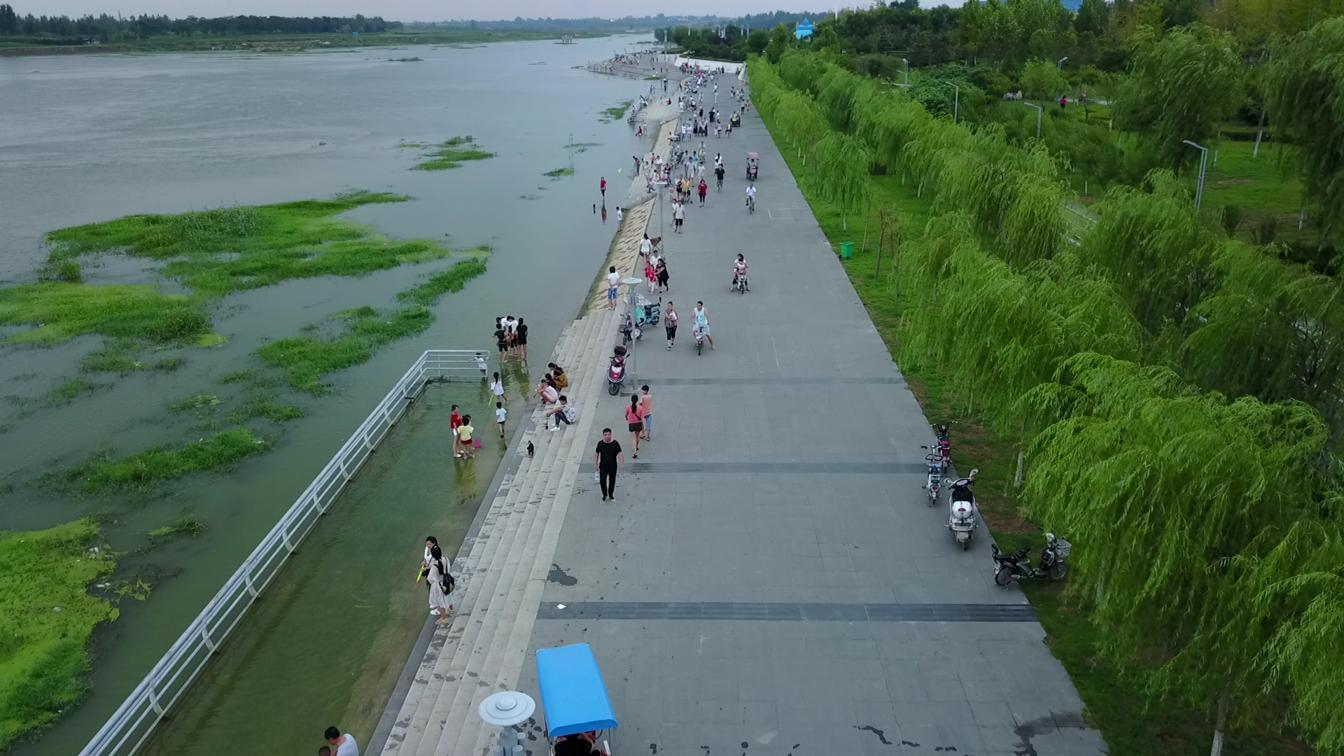

In [10]:

# ==========================================
# STEP 3: INSPECT VIDEO SEQUENCE
# ==========================================

from PIL import Image

# Get sequence name from annotation filename
sequence_name = os.path.splitext(sample_annotation)[0]

sample_sequence_path = os.path.join(
    SEQUENCE_DIR,
    sequence_name
)

print("Selected sequence:", sequence_name)
print("Sequence path:", sample_sequence_path)

# List image frames
frame_files = sorted([
    f for f in os.listdir(sample_sequence_path)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
])

print("\nTotal video frames:", len(frame_files))

print("\nFirst 10 frames:")

for frame in frame_files[:10]:
    print(frame)

# Display one frame
if frame_files:

    first_frame_path = os.path.join(
        sample_sequence_path,
        frame_files[0]
    )

    image = Image.open(first_frame_path)

    print("\nFrame dimensions:", image.size)

    display(image)


In [11]:

# STEP 4: VERIFY DATASET PAIRING

annotation_names = {
    os.path.splitext(f)[0]
    for f in os.listdir(ANNOTATION_DIR)
    if f.endswith(".txt")
}

sequence_names = {
    f for f in os.listdir(SEQUENCE_DIR)
    if os.path.isdir(os.path.join(SEQUENCE_DIR, f))
}

print("Total annotation files:", len(annotation_names))
print("Total sequence folders:", len(sequence_names))

print(
    "\nSequences without annotations:",
    sorted(sequence_names - annotation_names)
)

print(
    "\nAnnotations without sequences:",
    sorted(annotation_names - sequence_names)
)

if annotation_names == sequence_names:
    print("\nSUCCESS: All sequence and annotation names match!")
else:
    print("\nWARNING: Some sequence and annotation names do not match.")


Total annotation files: 56
Total sequence folders: 56

Sequences without annotations: []

Annotations without sequences: []

SUCCESS: All sequence and annotation names match!


Selected sequence: uav0000084_00000_v
Total image frames: 516

First 5 frames:
0000001.jpg
0000002.jpg
0000003.jpg
0000004.jpg
0000005.jpg


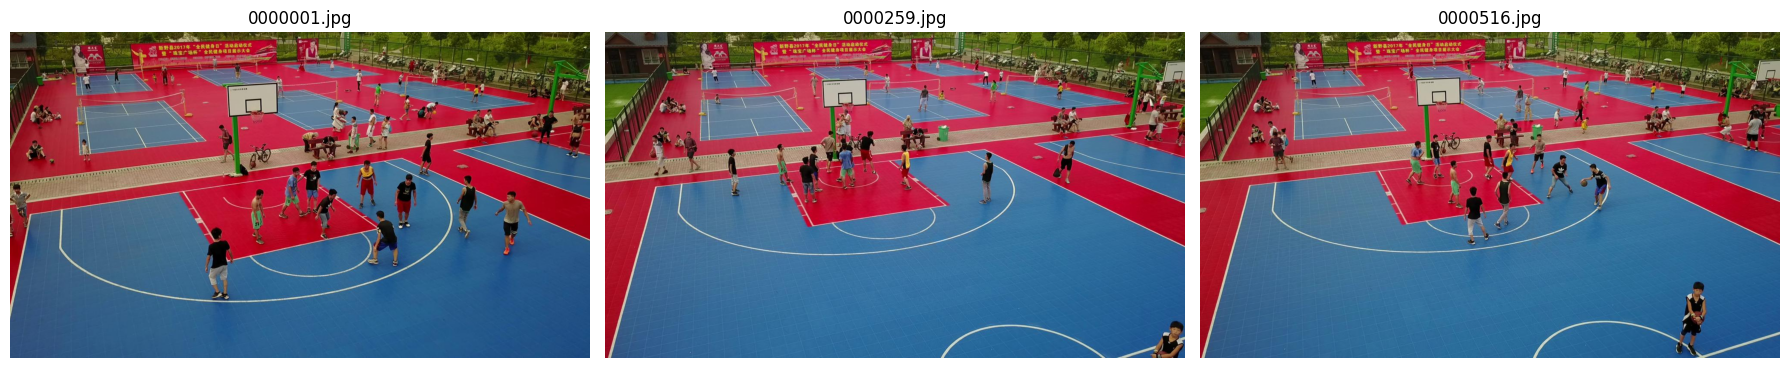

In [16]:

# STEP 5: INSPECT OUR SELECTED MOT SEQUENCE


import os
import matplotlib.pyplot as plt
from PIL import Image

# Select our first tracking sequence
SELECTED_SEQUENCE = "uav0000084_00000_v"

# Get its image folder
selected_sequence_path = os.path.join(
    SEQUENCE_DIR,
    SELECTED_SEQUENCE
)

# Get its annotation file
selected_annotation_path = os.path.join(
    ANNOTATION_DIR,
    SELECTED_SEQUENCE + ".txt"
)

# Find all image frames
frame_files = sorted([
    f for f in os.listdir(selected_sequence_path)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
])

print("Selected sequence:", SELECTED_SEQUENCE)
print("Total image frames:", len(frame_files))

print("\nFirst 5 frames:")
for frame in frame_files[:5]:
    print(frame)

# Display 3 frames from the sequence
sample_indices = [
    0,
    len(frame_files) // 2,
    len(frame_files) - 1
]

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for ax, index in zip(axes, sample_indices):

    frame_path = os.path.join(
        selected_sequence_path,
        frame_files[index]
    )

    image = Image.open(frame_path).convert("RGB")

    ax.imshow(image)
    ax.set_title(frame_files[index])
    ax.axis("off")

plt.tight_layout()
plt.show()


In [18]:
# Define the selected sequence folder path

SELECTED_SEQUENCE_PATH = os.path.join(
    SEQUENCE_DIR,
    SELECTED_SEQUENCE
)

# Verify that the folder exists
print("Selected sequence:", SELECTED_SEQUENCE)
print("Sequence path:", SELECTED_SEQUENCE_PATH)
print("Folder exists:", os.path.exists(SELECTED_SEQUENCE_PATH))


Selected sequence: uav0000084_00000_v
Sequence path: /content/drive/MyDrive/ResQVision/Datasets/Raw/VisDrone/Multi-Object tracking/VisDrone2019-MOT-train/sequences/uav0000084_00000_v
Folder exists: True


In [20]:

# STEP 5: YOLO26m + BYTETRACK
# FIRST 100 FRAMES

import os
import cv2
from ultralytics import YOLO
from tqdm.auto import tqdm

# 1. Load our existing flood-fine-tuned model
BEST_MODEL_PATH = (
    "/content/drive/MyDrive/ResQVision/Outputs/"
    "yolo26m_c2a_flood_finetune_960/weights/best.pt"
)
OUTPUT_DIR = os.path.join(
    "/content/drive/MyDrive/ResQVision/Outputs/"
)

if not os.path.exists(BEST_MODEL_PATH):
    raise FileNotFoundError(
        f"Model checkpoint not found: {BEST_MODEL_PATH}"
    )

model = YOLO(BEST_MODEL_PATH)

print("YOLO26m model loaded successfully!")

# 2. Get the selected sequence frames
frame_files = sorted([
    f for f in os.listdir(SELECTED_SEQUENCE_PATH)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
])

# Process only the first 100 frames
frame_files = frame_files[:100]

print("Frames selected:", len(frame_files))

# 3. Create output directory
TRACK_OUTPUT_DIR = os.path.join(
    OUTPUT_DIR,
    "bytetrack_first_test"
)

os.makedirs(TRACK_OUTPUT_DIR, exist_ok=True)

VIDEO_PATH = os.path.join(
    TRACK_OUTPUT_DIR,
    "first_100_frames_tracked.mp4"
)

# 4. Read the first frame to get video dimensions
first_frame_path = os.path.join(
    SELECTED_SEQUENCE_PATH,
    frame_files[0]
)

first_frame = cv2.imread(first_frame_path)

if first_frame is None:
    raise ValueError("Could not read the first frame.")

height, width = first_frame.shape[:2]

# 5. Prepare video writer
fourcc = cv2.VideoWriter_fourcc(*"mp4v")

video_writer = cv2.VideoWriter(
    VIDEO_PATH,
    fourcc,
    20,
    (width, height)
)

if not video_writer.isOpened():
    raise RuntimeError("Could not create output video.")

# 6. Process frames one by one
total_detections = 0
unique_track_ids = set()

try:

    for frame_name in tqdm(frame_files):

        frame_path = os.path.join(
            SELECTED_SEQUENCE_PATH,
            frame_name
        )

        frame = cv2.imread(frame_path)

        if frame is None:
            print("Skipping unreadable frame:", frame_name)
            continue

        # YOLO detects people and ByteTrack tracks them
        results = model.track(
            frame,
            persist=True,
            tracker="bytetrack.yaml",
            classes=[0],
            conf=0.25,
            imgsz=960,
            verbose=False
        )

        result = results[0]

        # Count detections and collect tracking IDs
        if result.boxes is not None:

            total_detections += len(result.boxes)

            if result.boxes.id is not None:

                ids = result.boxes.id.cpu().tolist()

                unique_track_ids.update(
                    int(track_id) for track_id in ids
                )

        # Draw boxes and tracking IDs
        annotated_frame = result.plot()

        video_writer.write(annotated_frame)

finally:
    video_writer.release()

# 7. Display results
print("\n========== TRACKING RESULTS ==========")

print("Frames processed:", len(frame_files))
print("Total detections:", total_detections)
print("Unique tracking IDs:", len(unique_track_ids))

print("\nOutput video saved at:")
print(VIDEO_PATH)


YOLO26m model loaded successfully!
Frames selected: 100


  0%|          | 0/100 [00:00<?, ?it/s]

requirements: Ultralytics requirement ['lap>=0.5.12'] not found, attempting AutoUpdate...
Using Python 3.13.18 environment at: /usr
Resolved 2 packages in 354ms
Prepared 1 package in 81ms
Installed 1 package in 1ms
 + lap==0.5.14

requirements: AutoUpdate success ✅ 0.9s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect


========== TRACKING RESULTS ==========
Frames processed: 100
Total detections: 1718
Unique tracking IDs: 93

Output video saved at:
/content/drive/MyDrive/ResQVision/Outputs/bytetrack_first_test/first_100_frames_tracked.mp4


In [23]:

import os
import cv2

print("Video exists:", os.path.exists(VIDEO_PATH))

if os.path.exists(VIDEO_PATH):

    print(
        "Video file size:",
        round(os.path.getsize(VIDEO_PATH) / (1024 * 1024), 2),
        "MB"
    )

    cap = cv2.VideoCapture(VIDEO_PATH)

    print("Video opened:", cap.isOpened())
    print("Frame count:", int(cap.get(cv2.CAP_PROP_FRAME_COUNT)))
    print("FPS:", cap.get(cv2.CAP_PROP_FPS))

    ret, frame = cap.read()

    print("First frame readable:", ret)

    if ret:
        print("Frame dimensions:", frame.shape)

    cap.release()


Video exists: True
Video file size: 12.26 MB
Video opened: True
Frame count: 100
FPS: 20.0
First frame readable: True
Frame dimensions: (756, 1344, 3)


In [25]:

import subprocess
import os

H264_VIDEO_PATH = os.path.join(
    TRACK_OUTPUT_DIR,
    "first_100_frames_tracked_h264.mp4"
)

command = [
    "ffmpeg",
    "-y",
    "-i", VIDEO_PATH,
    "-c:v", "libx264",
    "-preset", "fast",
    "-crf", "23",
    "-pix_fmt", "yuv420p",
    "-movflags", "+faststart",
    "-an",
    H264_VIDEO_PATH
]

result = subprocess.run(
    command,
    capture_output=True,
    text=True
)

if result.returncode == 0:
    print("Video converted successfully!")
    print("Output:", H264_VIDEO_PATH)
else:
    print("Video conversion failed:")
    print(result.stderr[-3000:])


Video converted successfully!
Output: /content/drive/MyDrive/ResQVision/Outputs/bytetrack_first_test/first_100_frames_tracked_h264.mp4


In [27]:
from IPython.display import Video, display

display(
    Video(
        H264_VIDEO_PATH,
        embed=True,
        width=900
    )
)



In [29]:

# ==========================================
# STEP 9: TRACKING ID CONSISTENCY CHECK
# ==========================================

from collections import Counter

# Load the existing model if needed
# Uses the same model and sequence as Step 8

test_frames = frame_files[:30]

frame_track_counts = []
all_track_ids = set()

for frame_name in test_frames:

    frame_path = os.path.join(
        SELECTED_SEQUENCE_PATH,
        frame_name
    )

    frame = cv2.imread(frame_path)

    if frame is None:
        continue

    results = model.track(
        frame,
        persist=True,
        tracker="bytetrack.yaml",
        classes=[0],
        conf=0.25,
        imgsz=1280,
        verbose=False
    )

    result = results[0]

    if result.boxes is not None and result.boxes.id is not None:

        ids = [
            int(x)
            for x in result.boxes.id.cpu().tolist()
        ]

    else:
        ids = []

    frame_track_counts.append(len(ids))
    all_track_ids.update(ids)

    print(
        frame_name,
        "| Active tracking IDs:",
        ids
    )

print("\n========== DIAGNOSTIC SUMMARY ==========")
print("Frames inspected:", len(frame_track_counts))
print("Unique IDs observed:", len(all_track_ids))
print("Average active tracks per frame:",
      round(sum(frame_track_counts) / max(len(frame_track_counts), 1), 2))
print("Highest ID observed:",
      max(all_track_ids) if all_track_ids else "None")


0000001.jpg | Active tracking IDs: [433, 487, 488, 489, 490, 493, 517, 141, 486, 494, 498]
0000002.jpg | Active tracking IDs: [433, 487, 488, 489, 490, 493, 517, 532, 141, 486, 494, 498]
0000003.jpg | Active tracking IDs: [433, 487, 488, 489, 490, 493, 517, 141, 486, 494, 498, 539, 543, 546]
0000004.jpg | Active tracking IDs: [433, 487, 488, 489, 490, 493, 517, 141, 486, 494, 539, 543, 546, 548, 532]
0000005.jpg | Active tracking IDs: [433, 487, 488, 489, 490, 493, 517, 141, 486, 494, 539, 543, 546, 548, 557, 560, 532]
0000006.jpg | Active tracking IDs: [433, 487, 488, 489, 490, 493, 517, 486, 494, 543, 546, 548, 557, 560, 532, 565, 567, 568, 367, 498]
0000007.jpg | Active tracking IDs: [433, 487, 489, 490, 493, 517, 494, 543, 546, 548, 560, 532, 567, 568, 583, 585, 141, 539]
0000008.jpg | Active tracking IDs: [433, 487, 489, 490, 493, 517, 494, 543, 560, 532, 567, 568, 583, 585, 488, 367, 498]
0000009.jpg | Active tracking IDs: [433, 487, 489, 490, 493, 517, 494, 543, 560, 532, 567, 5

In [30]:

# ==========================================
# STEP 10: FRESH 30-FRAME TRACKING TEST
# ==========================================

from ultralytics import YOLO
from collections import defaultdict
import os
import cv2

# 1. Load a fresh model instance
tracking_model = YOLO(BEST_MODEL_PATH)

print("Fresh YOLO26m model loaded!")

# 2. Select first 30 frames
test_frames = sorted([
    f for f in os.listdir(SELECTED_SEQUENCE_PATH)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
])[:30]

# 3. Store tracking information
all_track_ids = set()
track_occurrences = defaultdict(int)
frame_track_counts = []

# 4. Process frames in order
for frame_name in test_frames:

    frame_path = os.path.join(
        SELECTED_SEQUENCE_PATH,
        frame_name
    )

    frame = cv2.imread(frame_path)

    if frame is None:
        continue

    results = tracking_model.track(
        frame,
        persist=True,
        tracker="bytetrack.yaml",
        classes=[0],
        conf=0.25,
        imgsz=960,
        verbose=False
    )

    result = results[0]

    current_ids = []

    if result.boxes is not None and result.boxes.id is not None:

        current_ids = [
            int(track_id)
            for track_id in result.boxes.id.cpu().tolist()
        ]

    frame_track_counts.append(len(current_ids))

    for track_id in current_ids:

        all_track_ids.add(track_id)
        track_occurrences[track_id] += 1

    print(
        frame_name,
        "| Active tracks:", current_ids
    )

# 5. Display summary
print("\n========== FRESH TRACKING SUMMARY ==========")

print("Frames processed:", len(frame_track_counts))
print("Unique tracking IDs:", len(all_track_ids))

print(
    "Average active tracks per frame:",
    round(
        sum(frame_track_counts) / max(len(frame_track_counts), 1),
        2
    )
)

# How many IDs appeared in multiple frames?
repeated_ids = [
    track_id
    for track_id, count in track_occurrences.items()
    if count >= 2
]

print("IDs appearing in multiple frames:", len(repeated_ids))

print("\nFirst 15 tracking IDs and their occurrences:")

for track_id, count in list(track_occurrences.items())[:15]:

    print(
        "ID:", track_id,
        "| Appeared in:", count, "frames"
    )


Fresh YOLO26m model loaded!
0000001.jpg | Active tracks: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20]
0000002.jpg | Active tracks: [1, 2, 3, 4, 5, 6, 9, 10, 14, 19]
0000003.jpg | Active tracks: [1, 3, 4, 5, 6, 9, 10, 14, 8, 13, 15]
0000004.jpg | Active tracks: [1, 3, 4, 5, 6, 9, 8, 13, 15]
0000005.jpg | Active tracks: [1, 3, 4, 5, 6, 9, 13, 15, 31, 7, 2, 10]
0000006.jpg | Active tracks: [1, 3, 4, 5, 6, 9, 13, 15, 31, 36, 37, 7, 10]
0000007.jpg | Active tracks: [1, 3, 4, 5, 6, 9, 13, 15, 36, 37, 7, 10, 41]
0000008.jpg | Active tracks: [1, 3, 4, 5, 6, 9, 13, 15, 36, 37, 7, 10, 41, 8, 2, 31]
0000009.jpg | Active tracks: [1, 3, 4, 5, 6, 9, 13, 36, 37, 7, 10, 8, 16]
0000010.jpg | Active tracks: [1, 3, 4, 5, 6, 9, 37, 7, 10, 8, 16, 41]
0000011.jpg | Active tracks: [1, 3, 4, 5, 6, 9, 37, 7, 10, 16, 61, 62, 65, 18, 13, 36]
0000012.jpg | Active tracks: [1, 3, 4, 5, 9, 37, 7, 10, 16, 61, 62, 65, 18, 13, 36, 15, 41]
0000013.jpg | Active tracks: [1, 4, 5, 9, 7, 16, 65, 1

In [31]:

import os
import pandas as pd

# Selected MOT sequence
SEQUENCE_NAME = "uav0000084_00000_v"

# Dataset annotation directory
ANNOTATION_DIR = (
    "/content/drive/MyDrive/ResQVision/Datasets/Raw/VisDrone/"
    "Multi-Object tracking/VisDrone2019-MOT-train/annotations"
)

ANNOTATION_PATH = os.path.join(
    ANNOTATION_DIR,
    SEQUENCE_NAME + ".txt"
)

# Check whether the annotation file exists
if not os.path.exists(ANNOTATION_PATH):
    print("ERROR: Annotation file not found:")
    print(ANNOTATION_PATH)

else:
    # Read MOT annotations
    columns = [
        "frame",
        "target_id",
        "left",
        "top",
        "width",
        "height",
        "score",
        "category",
        "truncation",
        "occlusion"
    ]

    ground_truth = pd.read_csv(
        ANNOTATION_PATH,
        header=None,
        names=columns
    )

    # Keep valid person annotations:
    # Category 1 = pedestrian
    # Category 2 = people
    # Score 1 = valid annotation
    person_data = ground_truth[
        (ground_truth["category"].isin([1, 2])) &
        (ground_truth["score"] == 1) &
        (ground_truth["frame"] <= 30)
    ]

    print("========== GROUND TRUTH SUMMARY ==========")

    print("Sequence:", SEQUENCE_NAME)
    print("Total annotation rows:", len(ground_truth))
    print("Valid person annotations in first 30 frames:",
          len(person_data))

    print("Unique person IDs:",
          person_data["target_id"].nunique())

    print("\nPerson annotations per frame:")

    print(
        person_data.groupby("frame")
        .size()
        .head(30)
    )

    print("\nFirst 15 person annotations:")
    print(person_data.head(15).to_string(index=False))


========== GROUND TRUTH SUMMARY ==========
Sequence: uav0000084_00000_v
Total annotation rows: 30187
Valid person annotations in first 30 frames: 1628
Unique person IDs: 55

Person annotations per frame:
frame
1     54
2     54
3     54
4     54
5     54
6     54
7     54
8     54
9     54
10    54
11    54
12    54
13    54
14    54
15    54
16    54
17    54
18    54
19    54
20    54
21    55
22    55
23    55
24    55
25    55
26    55
27    55
28    55
29    54
30    54
dtype: int64

First 15 person annotations:
 frame  target_id  left  top  width  height  score  category  truncation  occlusion
     1          0     0  348     51     111      1         1           0          0
     2          0     0  348     51     111      1         1           0          0
     3          0     0  348     51     110      1         1           0          0
     4          0     1  348     51     110      1         1           0          0
     5          0     1  348     52     110      1       

In [32]:

print("========== MODEL CHECKPOINT CHECK ==========")

print("BEST_MODEL_PATH:", BEST_MODEL_PATH)

print("MODEL USED IN TRACKING:")
print(tracking_model.ckpt_path)


========== MODEL CHECKPOINT CHECK ==========
BEST_MODEL_PATH: /content/drive/MyDrive/ResQVision/Outputs/yolo26m_c2a_flood_finetune_960/weights/best.pt
MODEL USED IN TRACKING:
/content/drive/MyDrive/ResQVision/Outputs/yolo26m_c2a_flood_finetune_960/weights/best.pt


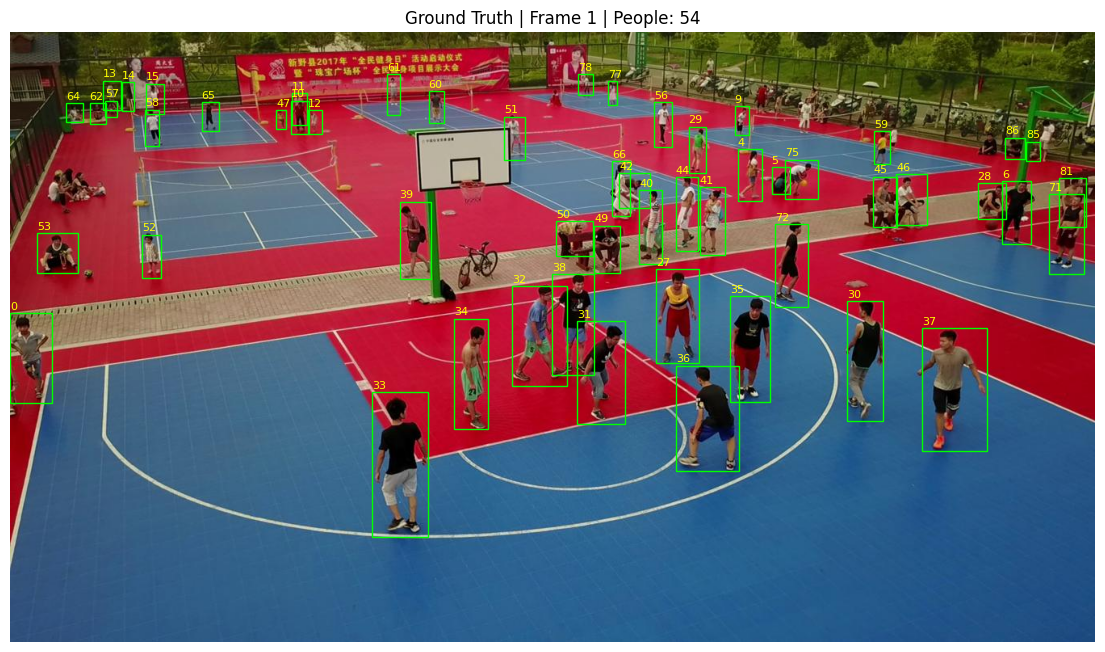

In [33]:

import cv2
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import os

# Display the first frame
frame_path = os.path.join(
    SELECTED_SEQUENCE_PATH,
    "0000001.jpg"
)

image = cv2.imread(frame_path)
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

fig, ax = plt.subplots(figsize=(14, 8))
ax.imshow(image)

# Get ground truth for frame 1
frame_annotations = person_data[
    person_data["frame"] == 1
]

for _, row in frame_annotations.iterrows():

    x = row["left"]
    y = row["top"]
    w = row["width"]
    h = row["height"]

    rect = patches.Rectangle(
        (x, y),
        w,
        h,
        linewidth=1,
        edgecolor="lime",
        facecolor="none"
    )

    ax.add_patch(rect)

    ax.text(
        x,
        max(0, y - 5),
        str(int(row["target_id"])),
        color="yellow",
        fontsize=8
    )

ax.set_title(
    f"Ground Truth | Frame 1 | "
    f"People: {len(frame_annotations)}"
)

ax.axis("off")
plt.show()


## We use C2A fine tuned model for this tracking but its not giving the result we want as our tracking baseline model so we are now going to use original yolo26m 960 res model

In [34]:

#LOAD THE CORRECT MOT MODEL

import os
from ultralytics import YOLO

# Original VisDrone-trained YOLO26m model
MOT_MODEL_PATH = (
    "/content/drive/MyDrive/ResQVision/Outputs/"
    "yolo26m_highres_960/weights/best.pt"
)

# Check whether the model exists
if not os.path.exists(MOT_MODEL_PATH):

    print("ERROR: VisDrone model checkpoint not found.")
    print(MOT_MODEL_PATH)

else:

    # Load a fresh model
    mot_model = YOLO(MOT_MODEL_PATH)

    print("VisDrone YOLO26m model loaded successfully!")
    print("Checkpoint:", MOT_MODEL_PATH)


VisDrone YOLO26m model loaded successfully!
Checkpoint: /content/drive/MyDrive/ResQVision/Outputs/yolo26m_highres_960/weights/best.pt


In [36]:

# VISDRONE MOT TRACKING TEST
# Save bounding boxes and tracking IDs for evaluation

from collections import defaultdict
import cv2
import os
import pandas as pd

# Select the first 30 frames
test_frames = sorted([
    f for f in os.listdir(SELECTED_SEQUENCE_PATH)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
])[:30]

# Store all predictions
predictions = []

all_track_ids = set()
track_occurrences = defaultdict(int)
frame_track_counts = []

# Process frames
for frame_name in test_frames:

    frame_path = os.path.join(
        SELECTED_SEQUENCE_PATH,
        frame_name
    )

    frame = cv2.imread(frame_path)

    if frame is None:
        print("Could not read:", frame_name)
        continue

    # Extract frame number from filename
    frame_number = int(
        os.path.splitext(frame_name)[0]
    )

    # Run YOLO26m + ByteTrack
    results = mot_model.track(
        frame,
        persist=True,
        tracker="bytetrack.yaml",
        classes=[0],
        conf=0.25,
        imgsz=960,
        verbose=False
    )

    result = results[0]
    current_ids = []

    if (
        result.boxes is not None
        and result.boxes.id is not None
    ):

        boxes = result.boxes.xyxy.cpu().tolist()
        track_ids = result.boxes.id.cpu().tolist()
        confidences = result.boxes.conf.cpu().tolist()

        for box, track_id, confidence in zip(
            boxes, track_ids, confidences
        ):

            track_id = int(track_id)

            x1, y1, x2, y2 = box

            # Save prediction details
            predictions.append({
                "frame": frame_number,
                "track_id": track_id,
                "x1": x1,
                "y1": y1,
                "x2": x2,
                "y2": y2,
                "confidence": confidence
            })

            current_ids.append(track_id)

            all_track_ids.add(track_id)
            track_occurrences[track_id] += 1

    frame_track_counts.append(len(current_ids))

    print(
        frame_name,
        "| Active tracks:", len(current_ids)
    )


# Convert predictions into a DataFrame
predictions_df = pd.DataFrame(predictions)

print("\n========== VISDRONE MOT RESULTS ==========")

print("Frames processed:", len(frame_track_counts))
print("Total detections:", len(predictions_df))
print("Unique tracking IDs:", len(all_track_ids))

print(
    "Average detections per frame:",
    round(
        sum(frame_track_counts) /
        max(len(frame_track_counts), 1),
        2
    )
)

repeated_ids = [
    track_id
    for track_id, count in track_occurrences.items()
    if count >= 2
]

print("IDs appearing in multiple frames:", len(repeated_ids))


# Save predictions to Google Drive
PREDICTION_OUTPUT_DIR = os.path.join(
    OUTPUT_DIR,
    "mot_tracking_evaluation"
)

os.makedirs(PREDICTION_OUTPUT_DIR, exist_ok=True)

PREDICTION_FILE = os.path.join(
    PREDICTION_OUTPUT_DIR,
    "bytetrack_predictions.csv"
)

predictions_df.to_csv(
    PREDICTION_FILE,
    index=False
)

print("\nPredictions saved successfully!")
print(PREDICTION_FILE)

print("\nFirst 10 predictions:")
display(predictions_df.head(10))


0000001.jpg | Active tracks: 26
0000002.jpg | Active tracks: 53
0000003.jpg | Active tracks: 56
0000004.jpg | Active tracks: 58
0000005.jpg | Active tracks: 56
0000006.jpg | Active tracks: 56
0000007.jpg | Active tracks: 56
0000008.jpg | Active tracks: 55
0000009.jpg | Active tracks: 56
0000010.jpg | Active tracks: 53
0000011.jpg | Active tracks: 56
0000012.jpg | Active tracks: 56
0000013.jpg | Active tracks: 55
0000014.jpg | Active tracks: 54
0000015.jpg | Active tracks: 52
0000016.jpg | Active tracks: 52
0000017.jpg | Active tracks: 53
0000018.jpg | Active tracks: 54
0000019.jpg | Active tracks: 57
0000020.jpg | Active tracks: 58
0000021.jpg | Active tracks: 57
0000022.jpg | Active tracks: 57
0000023.jpg | Active tracks: 57
0000024.jpg | Active tracks: 56
0000025.jpg | Active tracks: 58
0000026.jpg | Active tracks: 59
0000027.jpg | Active tracks: 59
0000028.jpg | Active tracks: 60
0000029.jpg | Active tracks: 56
0000030.jpg | Active tracks: 56

========== VISDRONE MOT RESULTS =======

,frame,track_id,x1,y1,x2,y2,confidence
0,1,1,795.066406,291.186005,849.190063,400.058990,0.816003
1,1,6,844.588074,119.742905,869.011597,175.469574,0.755997
2,1,7,800.783142,87.379814,819.530579,140.214798,0.754521
3,1,8,170.762894,97.134903,191.501099,141.932861,0.751441
4,1,9,1228.504272,184.954071,1268.998169,265.892151,0.747932
5,1,15,166.365982,248.038864,189.692627,298.839874,0.724084
6,1,16,775.106140,197.116959,810.128540,280.920685,0.736682
7,1,17,703.403992,350.940460,757.360046,462.354218,0.718178
8,1,20,1068.046509,179.687439,1105.038086,246.625504,0.610664
9,1,22,963.145508,156.584030,987.291382,206.167191,0.692461
